# 💻 Laptop Market Price Estimator
## Notebook complet : EDA → Feature Engineering → CatBoost → SHAP

**Auteur :** Data Science Portfolio Project  
**Dataset :** Computer Prices 2025 (~100 000 lignes, 33 colonnes)  
**Objectif :** Prédire le prix marché d'un laptop à partir de ses caractéristiques techniques

---
### Plan du notebook
1. Chargement & nettoyage des données
2. Analyse exploratoire (EDA)
3. Feature Engineering
4. Entraînement CatBoost
5. Évaluation du modèle
6. Analyse SHAP
7. Sauvegarde du modèle

## 📦 1. Imports & Configuration

In [1]:
# ─── Librairies standard ───────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# ─── Visualisation ────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# ─── Machine Learning ─────────────────────────────────────────────────────────
from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap
import joblib

# ─── Configuration globale des graphiques ─────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print('✅ Tous les imports sont OK')

✅ Tous les imports sont OK


## 📂 2. Chargement & Nettoyage des données

In [2]:
# ─── Chargement du dataset ────────────────────────────────────────────────────
df_raw = pd.read_csv('../data/computer_prices_all.csv')

print(f'📊 Shape brut : {df_raw.shape}')
print(f'📋 Colonnes : {list(df_raw.columns)}')
df_raw.head(3)

📊 Shape brut : (100000, 34)
📋 Colonnes : ['ID', 'device_type', 'brand', 'model', 'release_year', 'os', 'form_factor', 'cpu_brand', 'cpu_model', 'cpu_tier', 'cpu_cores', 'cpu_threads', 'cpu_base_ghz', 'cpu_boost_ghz', 'gpu_brand', 'gpu_model', 'gpu_tier', 'vram_gb', 'ram_gb', 'storage_type', 'storage_gb', 'storage_drive_count', 'display_type', 'display_size_in', 'resolution', 'refresh_hz', 'battery_wh', 'charger_watts', 'psu_watts', 'wifi', 'bluetooth', 'weight_kg', 'warranty_months', 'price']


,ID,device_type,brand,model,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,...,resolution,refresh_hz,battery_wh,charger_watts,psu_watts,wifi,bluetooth,weight_kg,warranty_months,price
0,0,Desktop,Samsung,Samsung Forge XDI,2022,Windows,ATX,Intel,Intel i5-11129,3,...,2560x1440,90,0,0,750,Wi-Fi 6,5.1,11.00,36,1383.99
1,1,Laptop,Samsung,Samsung Pro KM8,2022,Windows,Mainstream,Intel,Intel i7-11114,4,...,1920x1080,90,56,120,0,Wi-Fi 6,5.3,2.03,12,2274.99
2,2,Desktop,Lenovo,Lenovo Strix BIE,2024,macOS,SFF,AMD,AMD Ryzen 5 5168,2,...,3440x1440,120,0,0,850,Wi-Fi 6,5.0,7.00,24,1879.99


In [3]:
# ─── Aperçu général du dataset ────────────────────────────────────────────────
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   100000 non-null  int64  
 1   device_type          100000 non-null  object 
 2   brand                100000 non-null  object 
 3   model                100000 non-null  object 
 4   release_year         100000 non-null  int64  
 5   os                   100000 non-null  object 
 6   form_factor          100000 non-null  object 
 7   cpu_brand            100000 non-null  object 
 8   cpu_model            100000 non-null  object 
 9   cpu_tier             100000 non-null  int64  
 10  cpu_cores            100000 non-null  int64  
 11  cpu_threads          100000 non-null  int64  
 12  cpu_base_ghz         100000 non-null  float64
 13  cpu_boost_ghz        100000 non-null  float64
 14  gpu_brand            100000 non-null  object 
 15  gpu_model         

In [4]:
# ─── Statistiques descriptives ────────────────────────────────────────────────
df_raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,100000.0,NaN,NaN,NaN,49999.5,28867.657797,0.0,24999.75,49999.5,74999.25,99999.0
device_type,100000,2,Laptop,59844,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,100000,10,Lenovo,15992,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,100000,99036,Lenovo Think 0V5,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,100000.0,NaN,NaN,NaN,2022.32085,2.025761,2018.0,2021.0,2023.0,2024.0,2025.0
os,100000,4,Windows,71817,NaN,NaN,NaN,NaN,NaN,NaN,NaN
form_factor,100000,10,Mainstream,17819,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cpu_brand,100000,3,Intel,52774,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cpu_model,100000,26971,Apple M2 Pro,1389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cpu_tier,100000.0,NaN,NaN,NaN,3.15349,1.373175,1.0,2.0,3.0,4.0,6.0


In [5]:
# ─── Analyse des valeurs manquantes ──────────────────────────────────────────
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

print('🔍 Valeurs manquantes :')
print(missing_df)

🔍 Valeurs manquantes :
Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []


In [6]:
# ─── FILTRE : Garder uniquement les Laptops ───────────────────────────────────
# Contrainte métier : on se concentre exclusivement sur les laptops
df = df_raw[df_raw['device_type'] == 'Laptop'].copy()
print(f'✅ Après filtre Laptop : {df.shape[0]:,} lignes (sur {df_raw.shape[0]:,} au total)')
print(f'   Soit {df.shape[0]/df_raw.shape[0]*100:.1f}% du dataset original')

✅ Après filtre Laptop : 59,844 lignes (sur 100,000 au total)
   Soit 59.8% du dataset original


In [7]:
# ─── Suppression des colonnes inutiles ───────────────────────────────────────
# - 'ID'       : identifiant unique sans signal prédictif
# - 'model'    : trop granulaire, cardinalité trop haute, risque de leakage
# - 'psu_watts': non pertinent pour les laptops (concerne les desktops)
cols_to_drop = ['model', 'psu_watts']

# Vérifier lesquelles existent
existing_to_drop = [c for c in cols_to_drop if c in df.columns]
if 'ID' in df.columns:
    existing_to_drop.append('ID')

df.drop(columns=existing_to_drop, inplace=True)
print(f'🗑️  Colonnes supprimées : {existing_to_drop}')
print(f'📊 Shape après nettoyage : {df.shape}')

🗑️  Colonnes supprimées : ['model', 'psu_watts', 'ID']
📊 Shape après nettoyage : (59844, 31)


In [8]:
# ─── Traitement de la colonne 'resolution' ────────────────────────────────────
# Format actuel : '1920x1080' → on sépare en x_resolution et y_resolution
if 'resolution' in df.columns:
    res_split = df['resolution'].str.split('x', expand=True)
    df['x_resolution'] = pd.to_numeric(res_split[0], errors='coerce')
    df['y_resolution'] = pd.to_numeric(res_split[1], errors='coerce')
    df.drop(columns=['resolution'], inplace=True)
    print(f'✅ Résolution séparée : x_resolution & y_resolution')
    print(df[['x_resolution', 'y_resolution']].describe())

✅ Résolution séparée : x_resolution & y_resolution
       x_resolution  y_resolution
count  59844.000000  59844.000000
mean    2370.878952   1391.330125
std      605.741720    375.611766
min     1920.000000   1080.000000
25%     1920.000000   1080.000000
50%     1920.000000   1080.000000
75%     2560.000000   1600.000000
max     3840.000000   2160.000000


In [9]:
# ─── Suppression des doublons ─────────────────────────────────────────────────
n_before = len(df)
df.drop_duplicates(inplace=True)
print(f'🔄 Doublons supprimés : {n_before - len(df)}')
print(f'📊 Shape final : {df.shape}')

🔄 Doublons supprimés : 0
📊 Shape final : (59844, 32)


In [10]:
# ─── Traitement des valeurs manquantes ───────────────────────────────────────
# Stratégie : médiane pour les numériques, mode pour les catégorielles
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()

for col in num_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
        print(f'  🔢 {col} → fillna(median={median_val:.2f})')

for col in cat_cols:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)
        print(f'  📝 {col} → fillna(mode="{mode_val}")')

print(f'\n✅ Plus de valeurs manquantes : {df.isnull().sum().sum() == 0}')


✅ Plus de valeurs manquantes : True


## 📊 3. Analyse Exploratoire (EDA)

> L'EDA nous permet de comprendre la distribution des données, identifier les patterns et les relations entre les variables.

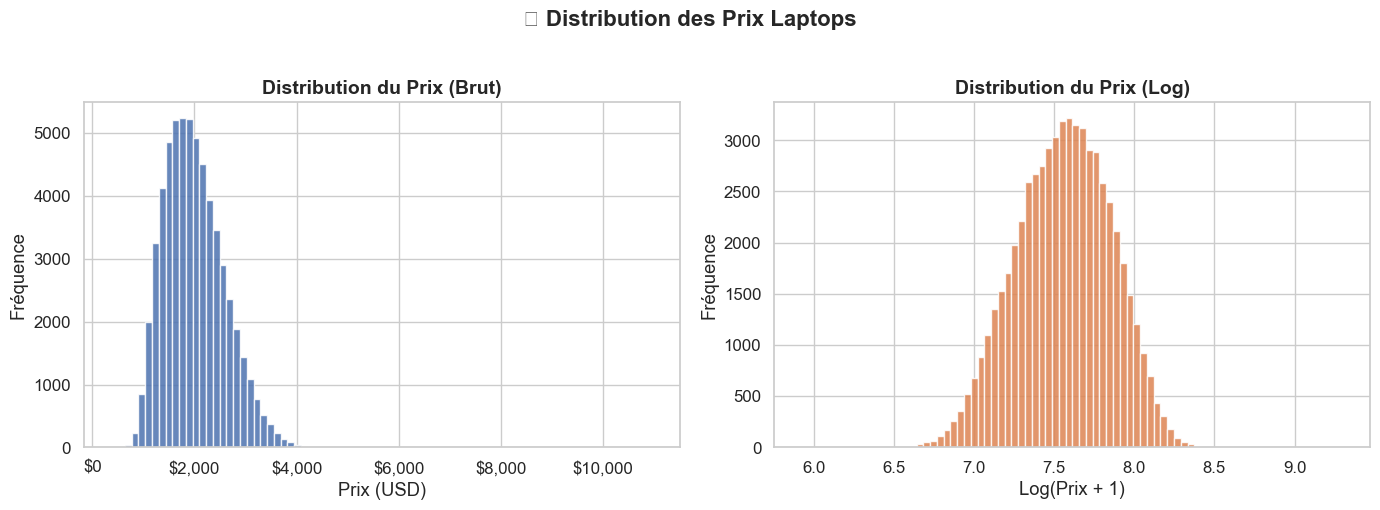

💰 Prix médian  : $1,935
💰 Prix moyen   : $2,002
💰 Prix min     : $373
💰 Prix max     : $10,985
💰 Ecart-type   : $600


In [11]:
# ─── 3.1 Distribution du prix ─────────────────────────────────────────────────
# La distribution du prix est souvent log-normale dans le marché tech
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution brute
axes[0].hist(df['price'], bins=80, color='#4C72B0', edgecolor='white', alpha=0.85)
axes[0].set_title('Distribution du Prix (Brut)')
axes[0].set_xlabel('Prix (USD)')
axes[0].set_ylabel('Fréquence')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Distribution log
axes[1].hist(np.log1p(df['price']), bins=80, color='#DD8452', edgecolor='white', alpha=0.85)
axes[1].set_title('Distribution du Prix (Log)')
axes[1].set_xlabel('Log(Prix + 1)')
axes[1].set_ylabel('Fréquence')

plt.suptitle('📈 Distribution des Prix Laptops', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../models/plot_price_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"💰 Prix médian  : ${df['price'].median():,.0f}")
print(f"💰 Prix moyen   : ${df['price'].mean():,.0f}")
print(f"💰 Prix min     : ${df['price'].min():,.0f}")
print(f"💰 Prix max     : ${df['price'].max():,.0f}")
print(f"💰 Ecart-type   : ${df['price'].std():,.0f}")

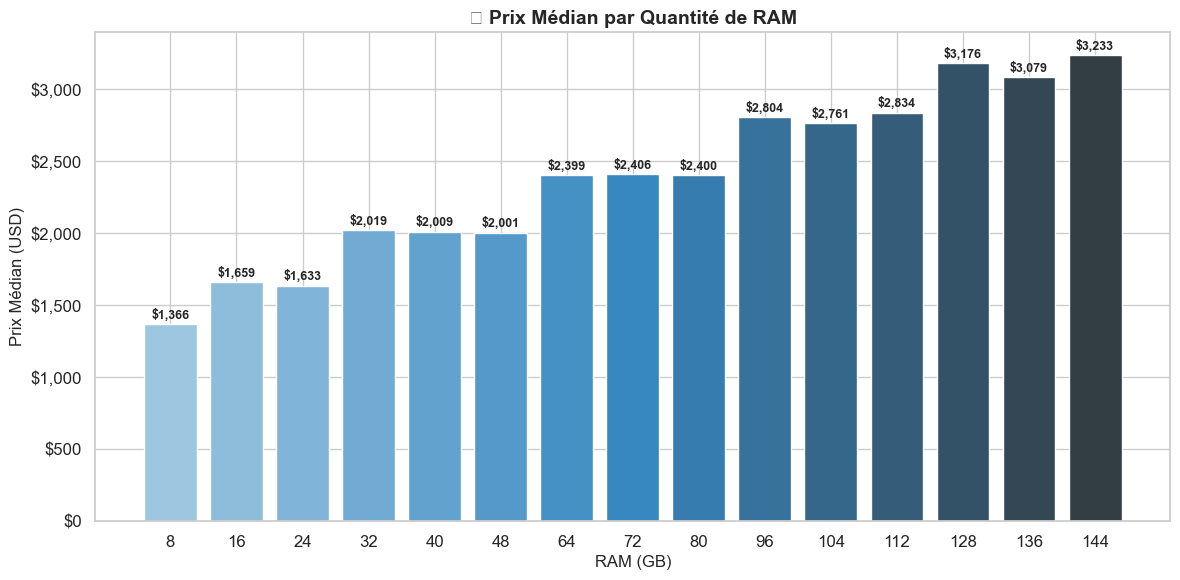

🔍 Observation : La RAM a une relation quasi-monotone avec le prix.
   Doubler la RAM augmente souvent le prix de 30-60%.


In [12]:
# ─── 3.2 Prix vs RAM ──────────────────────────────────────────────────────────
# La RAM est l'un des facteurs les plus déterminants du prix
fig, ax = plt.subplots(figsize=(12, 6))

ram_price = df.groupby('ram_gb')['price'].agg(['median', 'mean', 'count']).reset_index()
ram_price = ram_price[ram_price['count'] > 20]  # Filtre les catégories rares

bars = ax.bar(ram_price['ram_gb'].astype(str), ram_price['median'],
              color=sns.color_palette('Blues_d', len(ram_price)), edgecolor='white')
ax.set_xlabel('RAM (GB)', fontsize=12)
ax.set_ylabel('Prix Médian (USD)', fontsize=12)
ax.set_title('💾 Prix Médian par Quantité de RAM', fontsize=14, fontweight='bold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Annotations
for bar, val in zip(bars, ram_price['median']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
            f'${val:,.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('../models/plot_ram_vs_price.png', dpi=150, bbox_inches='tight')
plt.show()
print('🔍 Observation : La RAM a une relation quasi-monotone avec le prix.')
print('   Doubler la RAM augmente souvent le prix de 30-60%.')

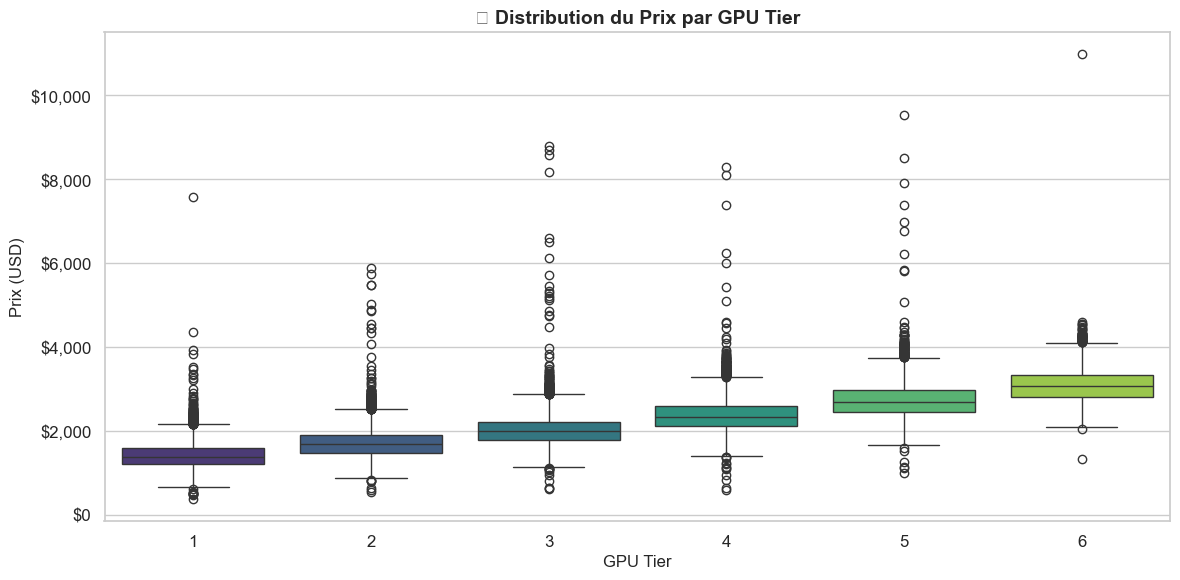

🔍 Observation : Le GPU Tier est fortement corrélé au prix.
   Les laptops avec GPU haut de gamme coûtent souvent 2-3x plus cher.


In [13]:
# ─── 3.3 Prix vs GPU Tier ─────────────────────────────────────────────────────
# Le GPU tier est une variable clé, surtout pour les laptops gaming
if 'gpu_tier' in df.columns:
    fig, ax = plt.subplots(figsize=(12, 6))
    
    gpu_order = sorted(df['gpu_tier'].dropna().unique())
    sns.boxplot(data=df, x='gpu_tier', y='price', order=gpu_order,
                palette='viridis', ax=ax)
    ax.set_xlabel('GPU Tier', fontsize=12)
    ax.set_ylabel('Prix (USD)', fontsize=12)
    ax.set_title('🎮 Distribution du Prix par GPU Tier', fontsize=14, fontweight='bold')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x:,.0f}'))
    
    plt.tight_layout()
    plt.savefig('../models/plot_gpu_tier_vs_price.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('🔍 Observation : Le GPU Tier est fortement corrélé au prix.')
    print('   Les laptops avec GPU haut de gamme coûtent souvent 2-3x plus cher.')

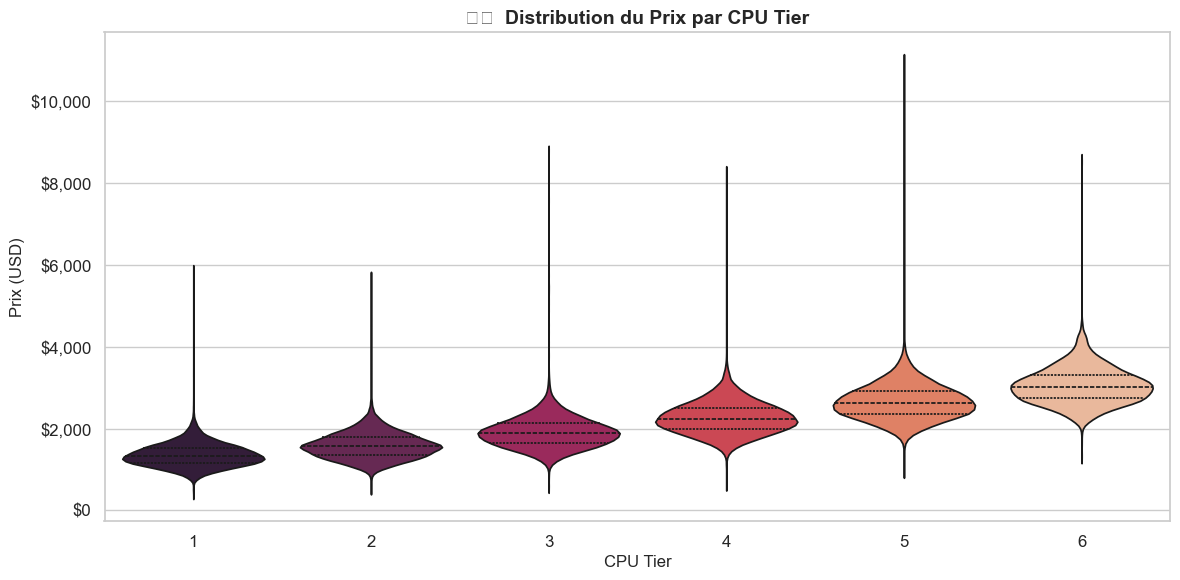

In [14]:
# ─── 3.4 Prix vs CPU Tier ─────────────────────────────────────────────────────
if 'cpu_tier' in df.columns:
    fig, ax = plt.subplots(figsize=(12, 6))
    
    cpu_order = sorted(df['cpu_tier'].dropna().unique())
    sns.violinplot(data=df, x='cpu_tier', y='price', order=cpu_order,
                   palette='rocket', inner='quartile', ax=ax)
    ax.set_xlabel('CPU Tier', fontsize=12)
    ax.set_ylabel('Prix (USD)', fontsize=12)
    ax.set_title('⚙️  Distribution du Prix par CPU Tier', fontsize=14, fontweight='bold')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x:,.0f}'))
    
    plt.tight_layout()
    plt.savefig('../models/plot_cpu_tier_vs_price.png', dpi=150, bbox_inches='tight')
    plt.show()

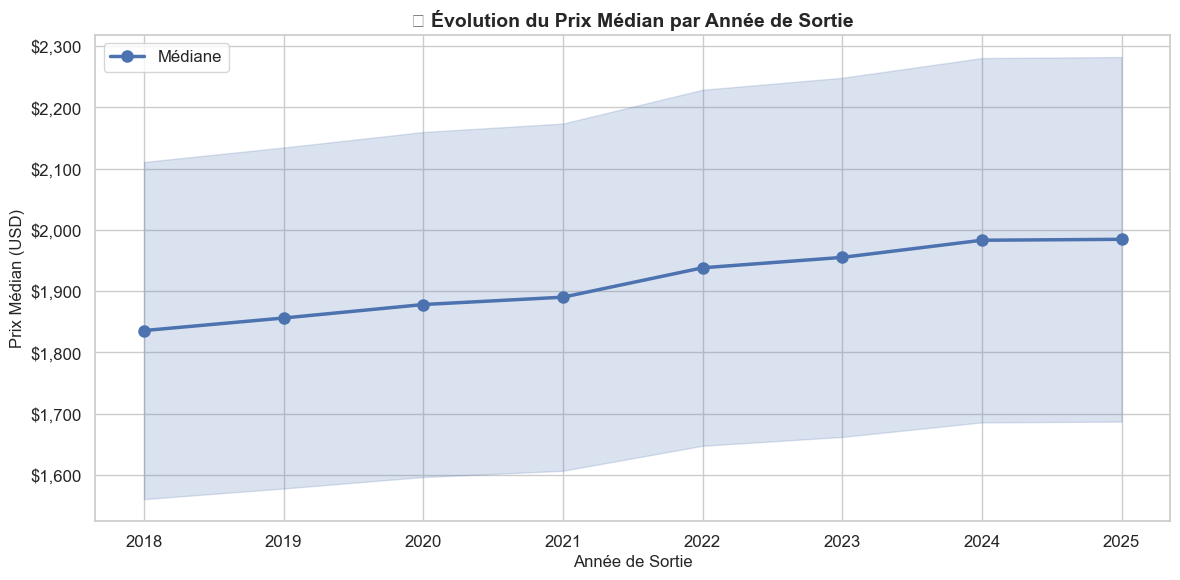

🔍 Observation : Les laptops récents sont en général plus chers,
   sauf lors des cycles de rafraîchissement produits.


In [15]:
# ─── 3.5 Prix vs Année de Sortie ─────────────────────────────────────────────
if 'release_year' in df.columns:
    fig, ax = plt.subplots(figsize=(12, 6))
    
    year_price = df.groupby('release_year')['price'].agg(['median', 'mean', 'count']).reset_index()
    year_price = year_price[year_price['count'] > 30]
    
    ax.plot(year_price['release_year'], year_price['median'], 'o-',
            color='#4C72B0', linewidth=2.5, markersize=8, label='Médiane')
    ax.fill_between(year_price['release_year'],
                    year_price['median'] * 0.85,
                    year_price['median'] * 1.15,
                    alpha=0.2, color='#4C72B0')
    
    ax.set_xlabel('Année de Sortie', fontsize=12)
    ax.set_ylabel('Prix Médian (USD)', fontsize=12)
    ax.set_title('📅 Évolution du Prix Médian par Année de Sortie', fontsize=14, fontweight='bold')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x:,.0f}'))
    ax.legend()
    
    plt.tight_layout()
    plt.savefig('../models/plot_year_vs_price.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('🔍 Observation : Les laptops récents sont en général plus chers,')
    print('   sauf lors des cycles de rafraîchissement produits.')

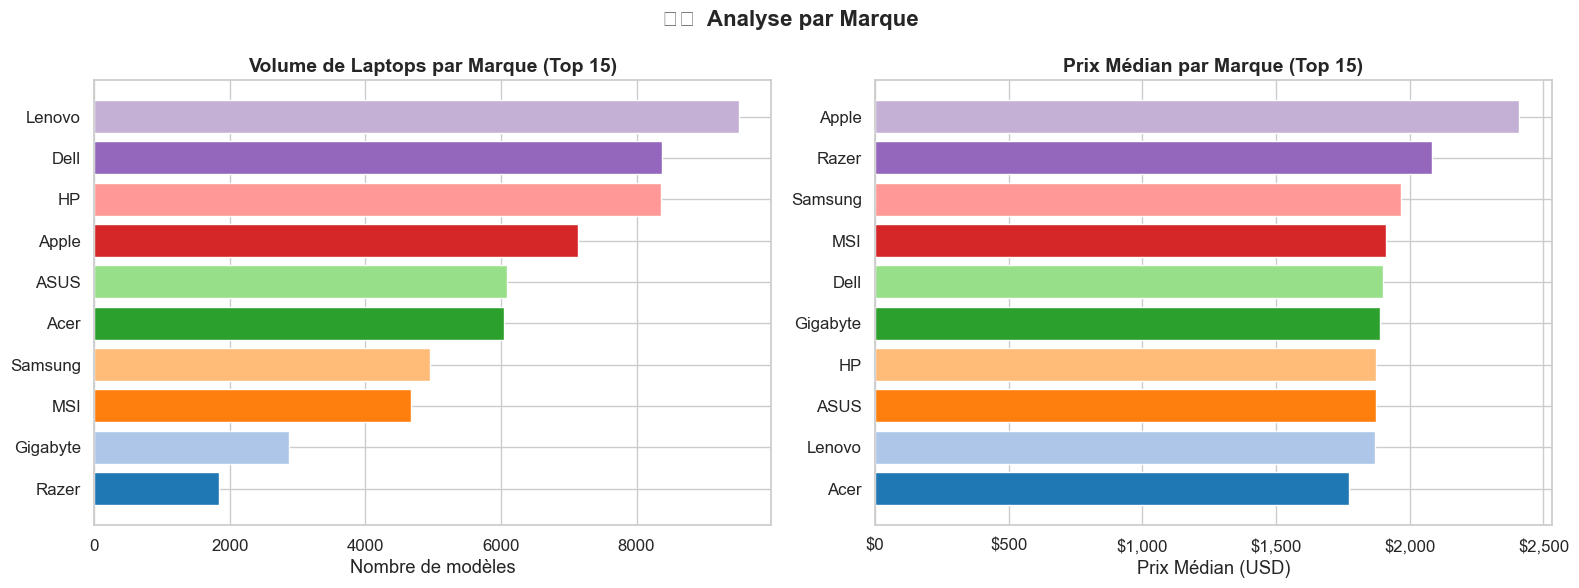

In [16]:
# ─── 3.6 Top Brands ───────────────────────────────────────────────────────────
if 'brand' in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Volume par brand
    brand_counts = df['brand'].value_counts().head(15)
    axes[0].barh(brand_counts.index[::-1], brand_counts.values[::-1],
                 color=sns.color_palette('tab20', 15))
    axes[0].set_title('Volume de Laptops par Marque (Top 15)')
    axes[0].set_xlabel('Nombre de modèles')
    
    # Prix médian par brand
    brand_price = df.groupby('brand')['price'].median().sort_values(ascending=False).head(15)
    axes[1].barh(brand_price.index[::-1], brand_price.values[::-1],
                 color=sns.color_palette('tab20', 15))
    axes[1].set_title('Prix Médian par Marque (Top 15)')
    axes[1].set_xlabel('Prix Médian (USD)')
    axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x:,.0f}'))
    
    plt.suptitle('🏷️  Analyse par Marque', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('../models/plot_brand_analysis.png', dpi=150, bbox_inches='tight')
    plt.show()

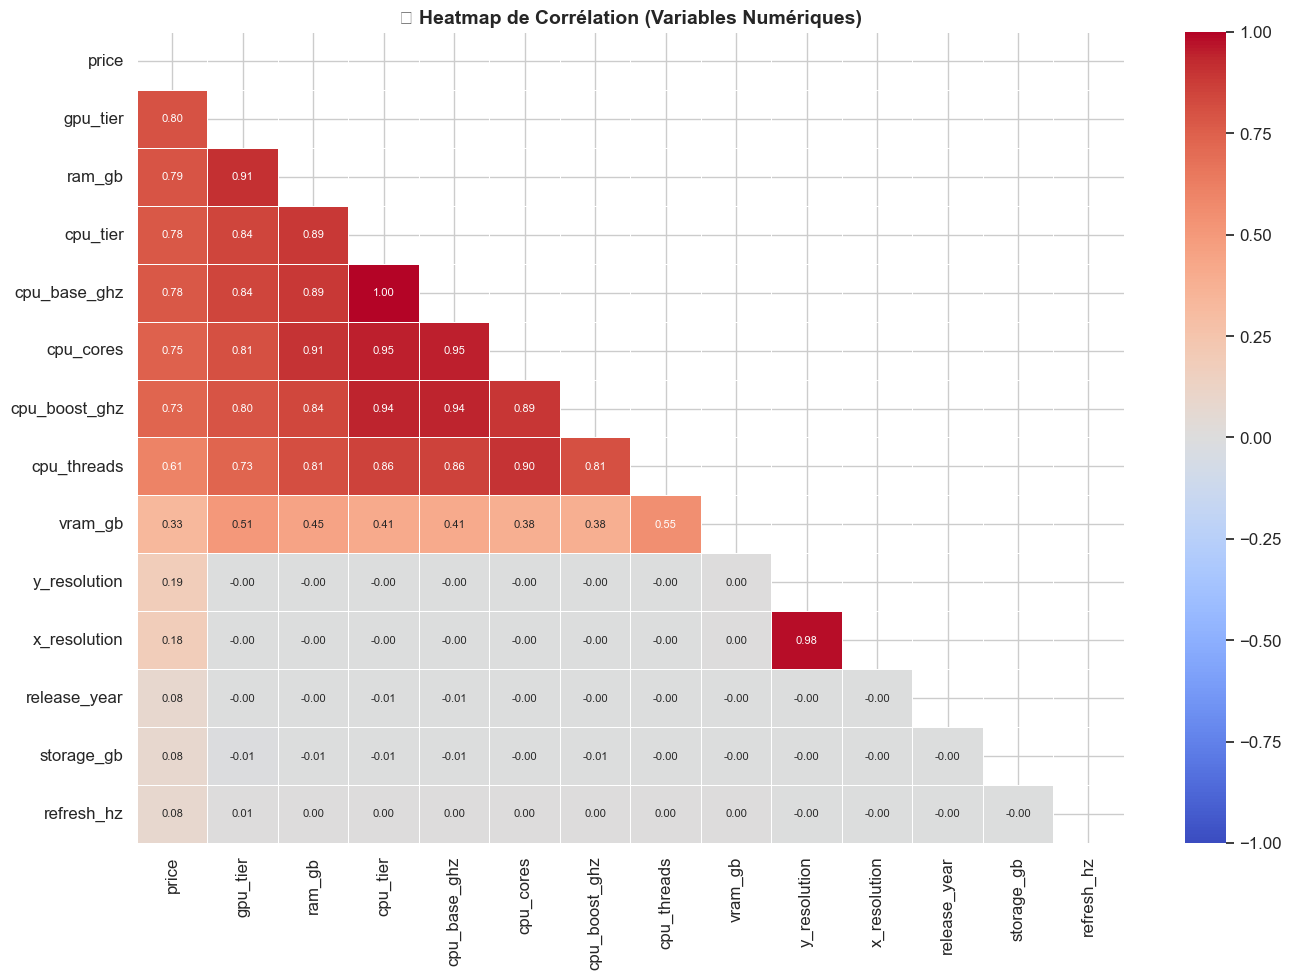


📊 Top 10 corrélations avec le prix :
price            1.000000
gpu_tier         0.802702
ram_gb           0.790750
cpu_tier         0.775637
cpu_base_ghz     0.775637
cpu_cores        0.749881
cpu_boost_ghz    0.730777
cpu_threads      0.605268
vram_gb          0.332274
y_resolution     0.187000
Name: price, dtype: float64


In [17]:
# ─── 3.7 Heatmap de Corrélation ───────────────────────────────────────────────
# Visualise les relations linéaires entre toutes les variables numériques
num_df = df.select_dtypes(include=np.number)

# Garder uniquement les colonnes corrélées avec le prix (>0.1)
corr_with_price = num_df.corr()['price'].abs().sort_values(ascending=False)
relevant_cols = corr_with_price[corr_with_price > 0.05].index.tolist()

fig, ax = plt.subplots(figsize=(14, 10))
corr_matrix = num_df[relevant_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # Masque triangle sup
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={'size': 8}, ax=ax)
ax.set_title('🔥 Heatmap de Corrélation (Variables Numériques)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../models/plot_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n📊 Top 10 corrélations avec le prix :')
print(corr_with_price.head(10))

## ⚙️ 4. Feature Engineering

> On crée des variables composites qui capturent mieux la puissance et la valeur des composants.

In [18]:
# ─── 4.1 CPU Power ────────────────────────────────────────────────────────────
# Produit des cœurs par la fréquence boost → proxy de la puissance CPU
if 'cpu_cores' in df.columns and 'cpu_boost_ghz' in df.columns:
    df['cpu_power'] = df['cpu_cores'] * df['cpu_boost_ghz']
    print(f'✅ cpu_power créé : min={df["cpu_power"].min():.1f}, max={df["cpu_power"].max():.1f}')

# ─── 4.2 GPU Power ────────────────────────────────────────────────────────────
# GPU tier × VRAM → puissance graphique effective
if 'gpu_tier' in df.columns and 'vram_gb' in df.columns:
    df['gpu_power'] = df['gpu_tier'] * df['vram_gb']
    print(f'✅ gpu_power créé : min={df["gpu_power"].min():.1f}, max={df["gpu_power"].max():.1f}')

# ─── 4.3 PPI (Pixel Per Inch) = Densité Écran ─────────────────────────────────
# Mesure la qualité de l'affichage : plus le PPI est élevé, meilleure est la netteté
if all(c in df.columns for c in ['x_resolution', 'y_resolution', 'display_size_in']):
    diag_pixels = np.sqrt(df['x_resolution']**2 + df['y_resolution']**2)
    df['ppi'] = diag_pixels / df['display_size_in'].replace(0, np.nan)
    df['ppi'].fillna(df['ppi'].median(), inplace=True)
    print(f'✅ ppi créé : min={df["ppi"].min():.0f}, max={df["ppi"].max():.0f} PPI')

# ─── 4.4 Storage Efficiency ───────────────────────────────────────────────────
# Stockage par disque → indicateur de configuration de stockage
if 'storage_gb' in df.columns and 'storage_drive_count' in df.columns:
    df['storage_per_drive'] = df['storage_gb'] / df['storage_drive_count'].replace(0, 1)
    print(f'✅ storage_per_drive créé : médiane={df["storage_per_drive"].median():.0f} GB/drive')

print(f'\n📊 Shape après feature engineering : {df.shape}')

✅ cpu_power créé : min=11.2, max=106.6
✅ gpu_power créé : min=0.0, max=96.0
✅ ppi créé : min=127, max=331 PPI
✅ storage_per_drive créé : médiane=512 GB/drive

📊 Shape après feature engineering : (59844, 36)


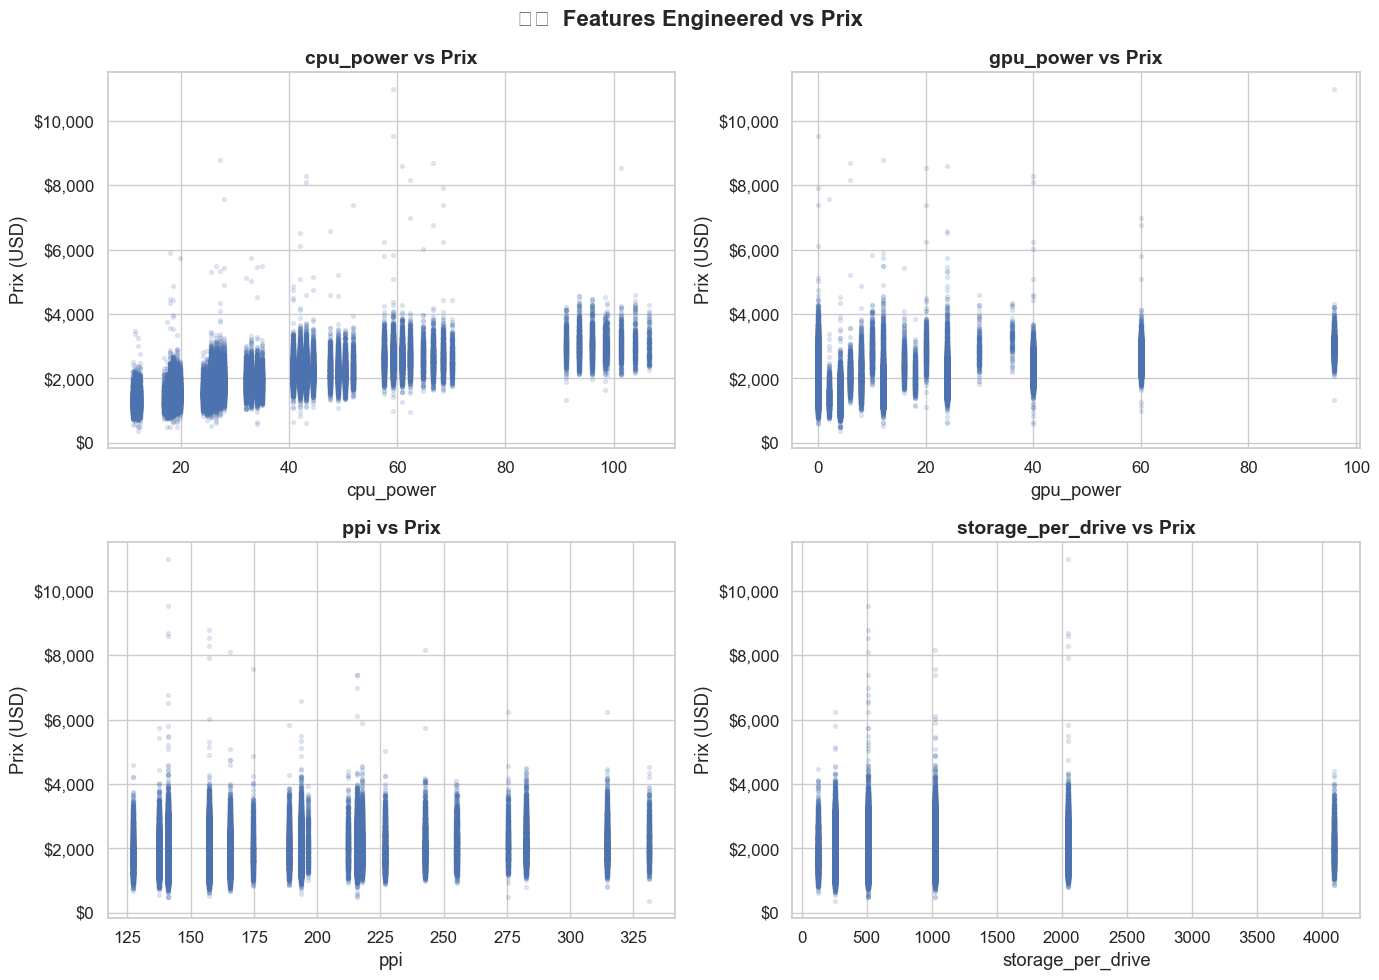

In [19]:
# ─── Visualisation des nouvelles features ─────────────────────────────────────
new_features = ['cpu_power', 'gpu_power', 'ppi', 'storage_per_drive']
existing_new = [f for f in new_features if f in df.columns]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feat in enumerate(existing_new[:4]):
    axes[i].scatter(df[feat], df['price'], alpha=0.15, s=8, color='#4C72B0')
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('Prix (USD)')
    axes[i].set_title(f'{feat} vs Prix')
    axes[i].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x:,.0f}'))

plt.suptitle('⚙️  Features Engineered vs Prix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../models/plot_engineered_features.png', dpi=150, bbox_inches='tight')
plt.show()

## 🤖 5. Entraînement CatBoost

> CatBoost est un algorithme de gradient boosting développé par Yandex.  
> Ses avantages : gestion native des catégorielles, très performant sur données tabulaires, résistant à l'overfitting.

In [20]:
# ─── Préparation X, y ────────────────────────────────────────────────────────
TARGET = 'price'

# Supprimer les colonnes non utiles pour la prédiction
drop_cols = [TARGET, 'device_type']  # device_type = toujours 'Laptop'
feature_cols = [c for c in df.columns if c not in drop_cols]

X = df[feature_cols].copy()
y = df[TARGET].copy()

print(f'📊 Features utilisées ({len(feature_cols)}) :')
print(feature_cols)

📊 Features utilisées (34) :
['brand', 'release_year', 'os', 'form_factor', 'cpu_brand', 'cpu_model', 'cpu_tier', 'cpu_cores', 'cpu_threads', 'cpu_base_ghz', 'cpu_boost_ghz', 'gpu_brand', 'gpu_model', 'gpu_tier', 'vram_gb', 'ram_gb', 'storage_type', 'storage_gb', 'storage_drive_count', 'display_type', 'display_size_in', 'refresh_hz', 'battery_wh', 'charger_watts', 'wifi', 'bluetooth', 'weight_kg', 'warranty_months', 'x_resolution', 'y_resolution', 'cpu_power', 'gpu_power', 'ppi', 'storage_per_drive']


In [21]:
# ─── Identification des variables catégorielles ───────────────────────────────
# CatBoost les gère nativement → pas besoin d'encodage manuel
cat_features = X.select_dtypes(include='object').columns.tolist()
num_features = X.select_dtypes(include=np.number).columns.tolist()

# CatBoost exige que les catégorielles soient des strings
for col in cat_features:
    X[col] = X[col].astype(str)

print(f'📝 Variables catégorielles ({len(cat_features)}) : {cat_features}')
print(f'🔢 Variables numériques ({len(num_features)}) : {num_features}')

📝 Variables catégorielles (10) : ['brand', 'os', 'form_factor', 'cpu_brand', 'cpu_model', 'gpu_brand', 'gpu_model', 'storage_type', 'display_type', 'wifi']
🔢 Variables numériques (24) : ['release_year', 'cpu_tier', 'cpu_cores', 'cpu_threads', 'cpu_base_ghz', 'cpu_boost_ghz', 'gpu_tier', 'vram_gb', 'ram_gb', 'storage_gb', 'storage_drive_count', 'display_size_in', 'refresh_hz', 'battery_wh', 'charger_watts', 'bluetooth', 'weight_kg', 'warranty_months', 'x_resolution', 'y_resolution', 'cpu_power', 'gpu_power', 'ppi', 'storage_per_drive']


In [22]:
# ─── Train/Test Split ─────────────────────────────────────────────────────────
# 80% train, 20% test → stratégie standard
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED
)

print(f'✅ Train : {X_train.shape[0]:,} lignes')
print(f'✅ Test  : {X_test.shape[0]:,} lignes')

✅ Train : 47,875 lignes
✅ Test  : 11,969 lignes


In [23]:
# ─── Création des Pools CatBoost ──────────────────────────────────────────────
# Le Pool est le format de données optimisé de CatBoost
cat_feat_indices = [X_train.columns.get_loc(c) for c in cat_features]

train_pool = Pool(X_train, y_train, cat_features=cat_feat_indices)
test_pool  = Pool(X_test,  y_test,  cat_features=cat_feat_indices)

print('✅ Pools CatBoost créés')

✅ Pools CatBoost créés


In [24]:
# ─── Entraînement du modèle CatBoost ─────────────────────────────────────────
# Hyperparamètres : balance entre performance et temps d'entraînement
model = CatBoostRegressor(
    iterations=1500,          # Nombre d'arbres
    learning_rate=0.05,       # Taux d'apprentissage (faible = plus robuste)
    depth=8,                  # Profondeur max des arbres
    l2_leaf_reg=3,            # Régularisation L2 anti-overfitting
    loss_function='RMSE',     # Fonction de perte
    eval_metric='RMSE',       # Métrique d'évaluation
    early_stopping_rounds=100,# Arrêt anticipé si pas d'amélioration
    random_seed=RANDOM_SEED,
    verbose=200               # Afficher les logs tous les 200 rounds
)

model.fit(
    train_pool,
    eval_set=test_pool,
    plot=False
)

print('\n✅ Entraînement terminé !')
print(f'   Meilleure itération : {model.best_iteration_}')

0:	learn: 577.1405776	test: 578.3247823	best: 578.3247823 (0)	total: 194ms	remaining: 4m 50s
200:	learn: 217.2615370	test: 212.9009618	best: 212.8994646 (199)	total: 19.4s	remaining: 2m 5s
400:	learn: 211.5042654	test: 211.9208309	best: 211.9176982 (396)	total: 40.6s	remaining: 1m 51s
600:	learn: 207.9563379	test: 211.7760341	best: 211.7744617 (599)	total: 59.9s	remaining: 1m 29s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 211.74295
bestIteration = 661

Shrink model to first 662 iterations.

✅ Entraînement terminé !
   Meilleure itération : 661


## 📏 6. Évaluation du Modèle

In [25]:
# ─── Métriques de performance ─────────────────────────────────────────────────
y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

def compute_metrics(y_true, y_pred, label=''):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100
    print(f'\n  📊 {label}')
    print(f'     MAE  : ${mae:,.0f}')
    print(f'     RMSE : ${rmse:,.0f}')
    print(f'     R²   : {r2:.4f}')
    print(f'     MAPE : {mape:.2f}%')
    return mae, rmse, r2, mape

mae_tr, rmse_tr, r2_tr, mape_tr = compute_metrics(y_train, y_pred_train, 'TRAIN')
mae_te, rmse_te, r2_te, mape_te = compute_metrics(y_test,  y_pred_test,  'TEST')

print(f'\n🎯 Overfitting gap R² : {r2_tr - r2_te:.4f}')


  📊 TRAIN
     MAE  : $138
     RMSE : $211
     R²   : 0.8762
     MAPE : 7.04%

  📊 TEST
     MAE  : $143
     RMSE : $212
     R²   : 0.8758
     MAPE : 7.25%

🎯 Overfitting gap R² : 0.0004


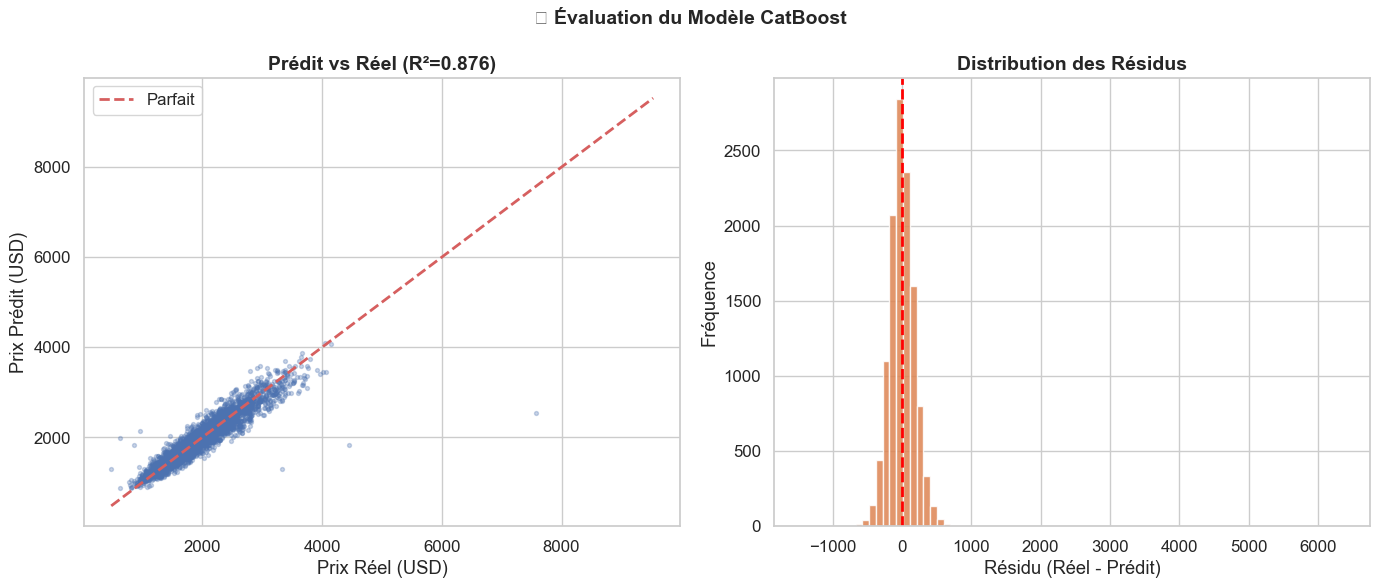

In [26]:
# ─── Graphique Prédictions vs Réalité ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Scatter plot
sample_idx = np.random.choice(len(y_test), min(3000, len(y_test)), replace=False)
axes[0].scatter(y_test.iloc[sample_idx], y_pred_test[sample_idx],
                alpha=0.3, s=8, color='#4C72B0')
min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Parfait')
axes[0].set_xlabel('Prix Réel (USD)')
axes[0].set_ylabel('Prix Prédit (USD)')
axes[0].set_title(f'Prédit vs Réel (R²={r2_te:.3f})')
axes[0].legend()

# Résidus
residuals = y_test.values - y_pred_test
axes[1].hist(residuals, bins=80, color='#DD8452', edgecolor='white', alpha=0.85)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('Résidu (Réel - Prédit)')
axes[1].set_ylabel('Fréquence')
axes[1].set_title('Distribution des Résidus')

plt.suptitle('🎯 Évaluation du Modèle CatBoost', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../models/plot_model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

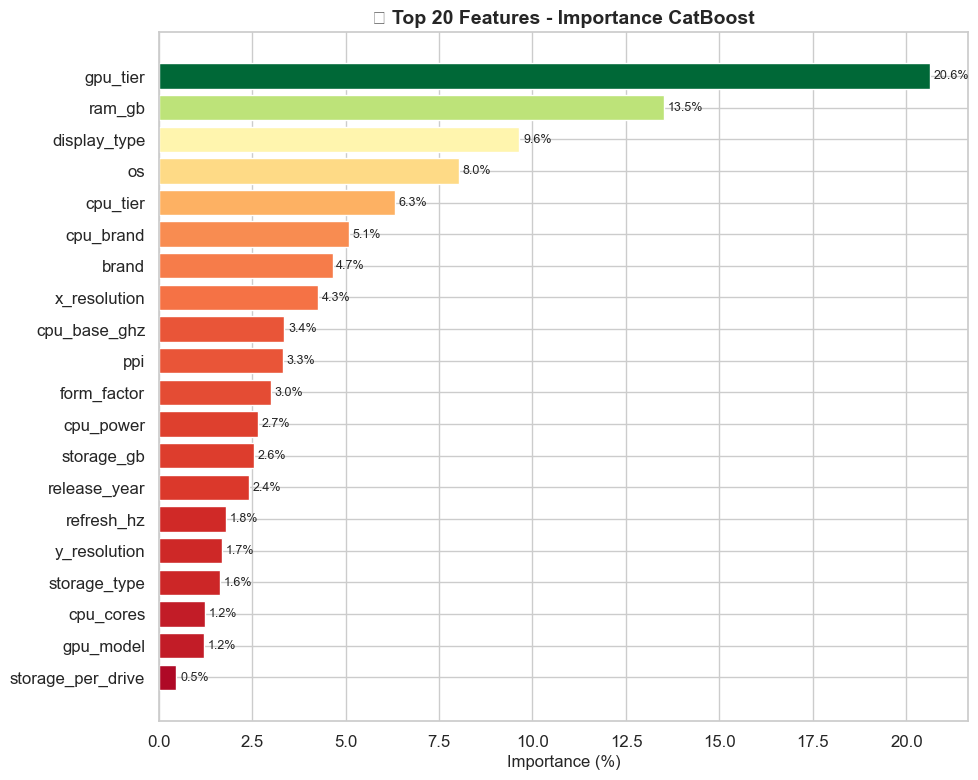

In [27]:
# ─── Feature Importance CatBoost ──────────────────────────────────────────────
feat_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': model.get_feature_importance()
}).sort_values('importance', ascending=True).tail(20)

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(feat_importance['feature'], feat_importance['importance'],
               color=plt.cm.RdYlGn(feat_importance['importance'] / feat_importance['importance'].max()))
ax.set_xlabel('Importance (%)', fontsize=12)
ax.set_title('🏆 Top 20 Features - Importance CatBoost', fontsize=14, fontweight='bold')

for bar, val in zip(bars, feat_importance['importance']):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('../models/plot_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## 🔮 7. Analyse SHAP

> SHAP (SHapley Additive exPlanations) permet d'expliquer les prédictions du modèle de manière interprétable.  
> Pour chaque feature, SHAP mesure sa contribution (positive ou négative) à la prédiction finale.

In [28]:
# ─── Calcul des valeurs SHAP ──────────────────────────────────────────────────
# On utilise un sous-ensemble pour la rapidité
sample_size = min(1000, len(X_test))
X_shap = X_test.iloc[:sample_size].copy()

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_shap)

print(f'✅ SHAP calculé sur {sample_size} exemples')

✅ SHAP calculé sur 1000 exemples


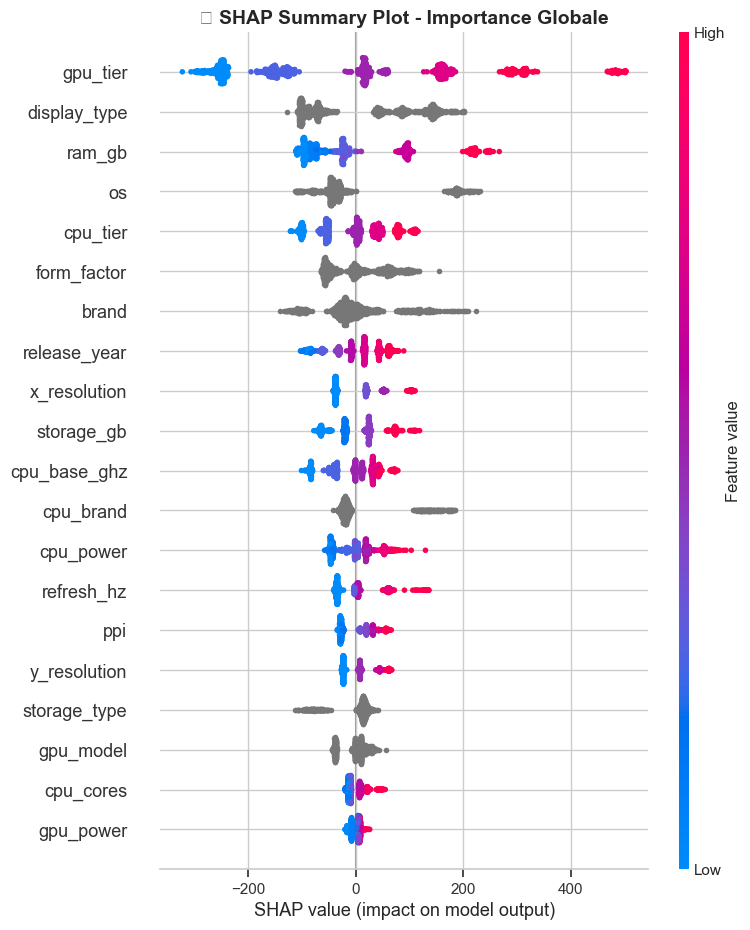

🔍 Lecture : Rouge = valeur haute, Bleu = valeur basse
   Position sur X = contribution au prix prédit


In [29]:
# ─── 7.1 SHAP Summary Plot (global) ──────────────────────────────────────────
# Montre l'importance globale et la direction de l'effet de chaque feature
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_shap, show=False, max_display=20)
plt.title('🔮 SHAP Summary Plot - Importance Globale', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../models/plot_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('🔍 Lecture : Rouge = valeur haute, Bleu = valeur basse')
print('   Position sur X = contribution au prix prédit')

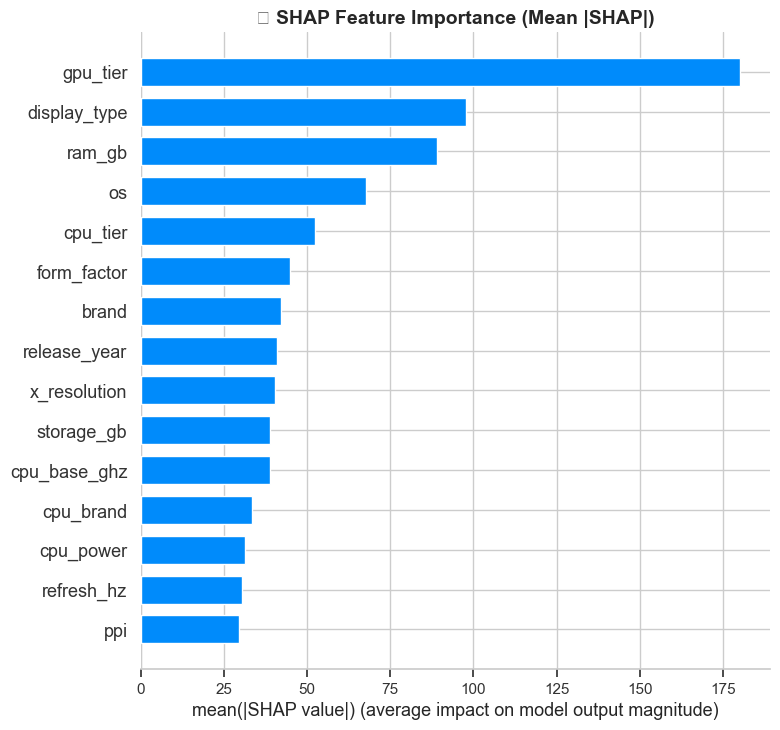

In [30]:
# ─── 7.2 SHAP Bar Plot ────────────────────────────────────────────────────────
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_shap, plot_type='bar', show=False, max_display=15)
plt.title('🏆 SHAP Feature Importance (Mean |SHAP|)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../models/plot_shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()

🎯 Prédiction pour le laptop #0
   Prix prédit  : $2,624
   Prix réel    : $2,691
   Valeur base  : $2,002 (prix moyen dataset)


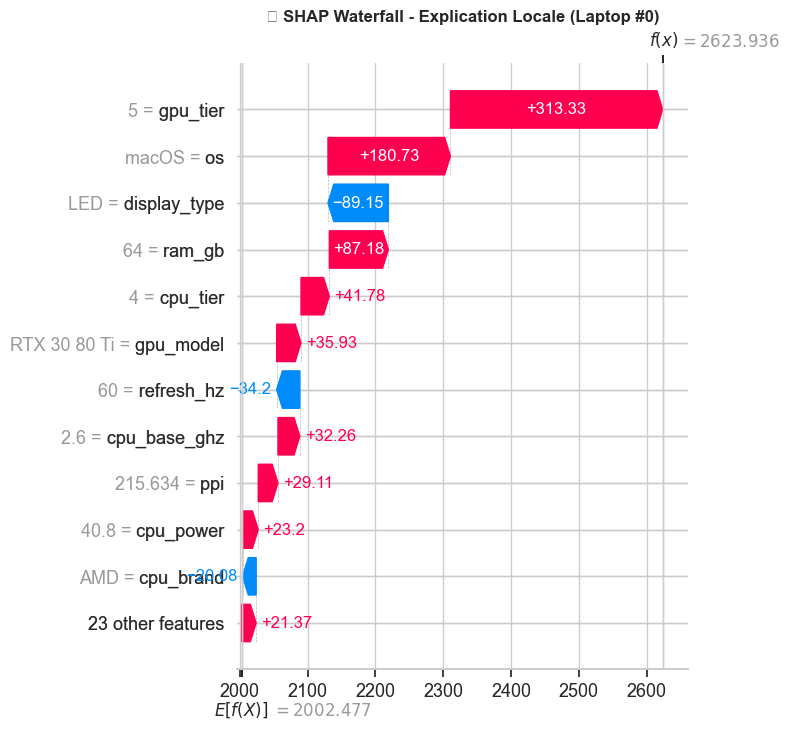

In [31]:
# ─── 7.3 SHAP Waterfall Plot (explication locale) ────────────────────────────
# Explique UNE prédiction spécifique
sample_idx = 0
expected_value = explainer.expected_value
if isinstance(expected_value, (list, np.ndarray)):
    expected_value = expected_value[0]

print(f'🎯 Prédiction pour le laptop #{sample_idx}')
print(f'   Prix prédit  : ${model.predict(X_shap.iloc[[sample_idx]])[0]:,.0f}')
print(f'   Prix réel    : ${y_test.iloc[sample_idx]:,.0f}')
print(f'   Valeur base  : ${expected_value:,.0f} (prix moyen dataset)')

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[sample_idx],
        base_values=expected_value,
        data=X_shap.iloc[sample_idx].values,
        feature_names=X_shap.columns.tolist()
    ),
    show=False,
    max_display=12
)
plt.title(f'💧 SHAP Waterfall - Explication Locale (Laptop #{sample_idx})',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../models/plot_shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()

## 💾 8. Sauvegarde du Modèle

In [33]:
# ─── Sauvegarde du modèle et des métadonnées ─────────────────────────────────
import joblib
import os

# Métadonnées utiles pour l'application Streamlit
model_metadata = {
    'model': model,
    'feature_columns': feature_cols,
    'cat_features': cat_features,
    'num_features': num_features,
    'cat_feat_indices': cat_feat_indices,
    'metrics': {
        'mae_test': mae_te,
        'rmse_test': rmse_te,
        'r2_test': r2_te,
        'mape_test': mape_te
    },
    'feature_importance': feat_importance.to_dict('records'),
    'train_size': len(X_train),
    'test_size': len(X_test),
    'price_stats': {
        'min': float(df['price'].min()),
        'max': float(df['price'].max()),
        'median': float(df['price'].median()),
        'mean': float(df['price'].mean()),
        'std': float(df['price'].std()),
        'all_prices': df['price'].tolist()
    },
    'brand_options': sorted(df['brand'].unique().tolist()) if 'brand' in df.columns else [],
    'os_options': sorted(df['os'].unique().tolist()) if 'os' in df.columns else [],
}

joblib.dump(model_metadata, '../models/laptop_price_model.pkl')
print('✅ Modèle sauvegardé → ../models/laptop_price_model.pkl')
print(f'   Taille fichier : {os.path.getsize("../models/laptop_price_model.pkl") / 1024**2:.1f} MB')

✅ Modèle sauvegardé → ../models/laptop_price_model.pkl
   Taille fichier : 31.5 MB


In [34]:
# ─── Résumé final ─────────────────────────────────────────────────────────────
print('='*60)
print('  🏁 RÉSUMÉ DU PROJET - LAPTOP PRICE ESTIMATOR')
print('='*60)
print(f'  Dataset      : {len(df):,} laptops')
print(f'  Features     : {len(feature_cols)} variables')
print(f'  Modèle       : CatBoostRegressor ({model.best_iteration_} arbres)')
print(f'  MAE Test     : ${mae_te:,.0f}')
print(f'  RMSE Test    : ${rmse_te:,.0f}')
print(f'  R² Test      : {r2_te:.4f}')
print(f'  MAPE Test    : {mape_te:.2f}%')
print('='*60)
print('  ✅ Notebook terminé avec succès !')
print('  🚀 Lancez maintenant : streamlit run app.py')
print('='*60)

  🏁 RÉSUMÉ DU PROJET - LAPTOP PRICE ESTIMATOR
  Dataset      : 59,844 laptops
  Features     : 34 variables
  Modèle       : CatBoostRegressor (661 arbres)
  MAE Test     : $143
  RMSE Test    : $212
  R² Test      : 0.8758
  MAPE Test    : 7.25%
  ✅ Notebook terminé avec succès !
  🚀 Lancez maintenant : streamlit run app.py
